#### Importing Libraries

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


#### Configuring Project Paths

In [2]:
project_dir = Path("..")

processed_dir = project_dir / "data" / "processed"
models_dir = project_dir / "models"
reports_dir = project_dir / "reports"
figures_dir = reports_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

project_paths = {
    "Processed Data": processed_dir,
    "Models": models_dir,
    "Reports": reports_dir,
    "Figures": figures_dir
}

for name, path in project_paths.items():
    status = "Found" if path.is_dir() else "Missing"
    print(f"{name}: {status}")

Processed Data: Found
Models: Found
Reports: Found
Figures: Found


## 2. Loading the Selected Model

#### Loading and Inspecting the Final Pipeline

In [3]:
model_path = models_dir / "final_logistic_regression_pipeline.joblib"

final_pipeline = joblib.load(model_path)

print("Final model loaded successfully.\n")

print("Pipeline Components:")
for step_name, estimator in final_pipeline.named_steps.items():
    print(f"- {step_name}: {type(estimator).__name__}")

print(f"\nTotal pipeline steps: {len(final_pipeline.steps)}")
print(f"Supported intent classes: {len(final_pipeline.classes_)}")

Final model loaded successfully.

Pipeline Components:
- tfidf: TfidfVectorizer
- classifier: LogisticRegression

Total pipeline steps: 2
Supported intent classes: 27


#### Inspecting TF-IDF Features and Model Coefficients

In [4]:
tfidf_vectorizer = final_pipeline.named_steps["tfidf"]
classifier = final_pipeline.named_steps["classifier"]

feature_names = tfidf_vectorizer.get_feature_names_out()
intent_classes = classifier.classes_
coefficients = classifier.coef_

print("TF-IDF Configuration")
print(f"Analyzer: {tfidf_vectorizer.analyzer}")
print(f"N-gram Range: {tfidf_vectorizer.ngram_range}")
print(f"Total Features: {len(feature_names):,}")

print("\nLogistic Regression Configuration")
print(f"Intent Classes: {len(intent_classes)}")
print(f"Coefficient Matrix Shape: {coefficients.shape}")
print(f"Regularization Strength (C): {classifier.C}")
print(f"Maximum Iterations: {classifier.max_iter}")

print("\nSample Character N-grams:")
print(feature_names[:15])

TF-IDF Configuration
Analyzer: char_wb
N-gram Range: (3, 5)
Total Features: 6,190

Logistic Regression Configuration
Intent Classes: 27
Coefficient Matrix Shape: (27, 6190)
Regularization Strength (C): 5.0
Maximum Iterations: 1000

Sample Character N-grams:
[' , ' ' ? ' ' a ' ' aa' ' aan' ' ab' ' abi' ' abil' ' abo' ' abou' ' ac'
 ' acc' ' acce' ' acco' ' accv']


## 3. Global Feature Importance Analysis

#### Identifying the Most Influential Character N-grams by Intent

In [5]:
top_n = 10
top_features_records = []

for class_idx, intent in enumerate(intent_classes):
    class_coefficients = coefficients[class_idx]
    top_indices = np.argsort(class_coefficients)[-top_n:][::-1]

    for rank, feature_idx in enumerate(top_indices, start=1):
        top_features_records.append({
            "Intent": intent,
            "Rank": rank,
            "Character N-gram": feature_names[feature_idx],
            "Coefficient": class_coefficients[feature_idx]
        })

top_features_df = pd.DataFrame(top_features_records)

print(f"Intent classes analyzed: {len(intent_classes)}")
print(f"Top features per intent: {top_n}")
print(f"Total feature records: {len(top_features_df)}")

display(top_features_df.head(30).round(4))

Intent classes analyzed: 27
Top features per intent: 10
Total feature records: 270


,Intent,Rank,Character N-gram,Coefficient
0,cancel_order,1,ncel,2.5362
1,cancel_order,2,cel,2.5362
2,cancel_order,3,el,2.5140
3,cancel_order,4,canc,2.2969
4,cancel_order,5,canc,2.2957
5,cancel_order,6,anc,2.2927
6,cancel_order,7,ancel,2.0445
7,cancel_order,8,cance,2.0432
8,cancel_order,9,ance,2.0419
9,cancel_order,10,ncel,2.0404


#### Observations
- **Intent-specific character patterns are evident**, with cancellation, modification, and shipping-related n-grams receiving strong positive coefficients for their respective classes.
- **Character-level features capture meaningful word fragments**, allowing the model to recognize intent-related terminology without relying exclusively on complete words.
- **Key Finding:** The learned coefficients provide interpretable evidence of how the model distinguishes customer support intents, although individual feature weights do not directly represent prediction probabilities.

#### Visualizing the Most Influential Character N-grams

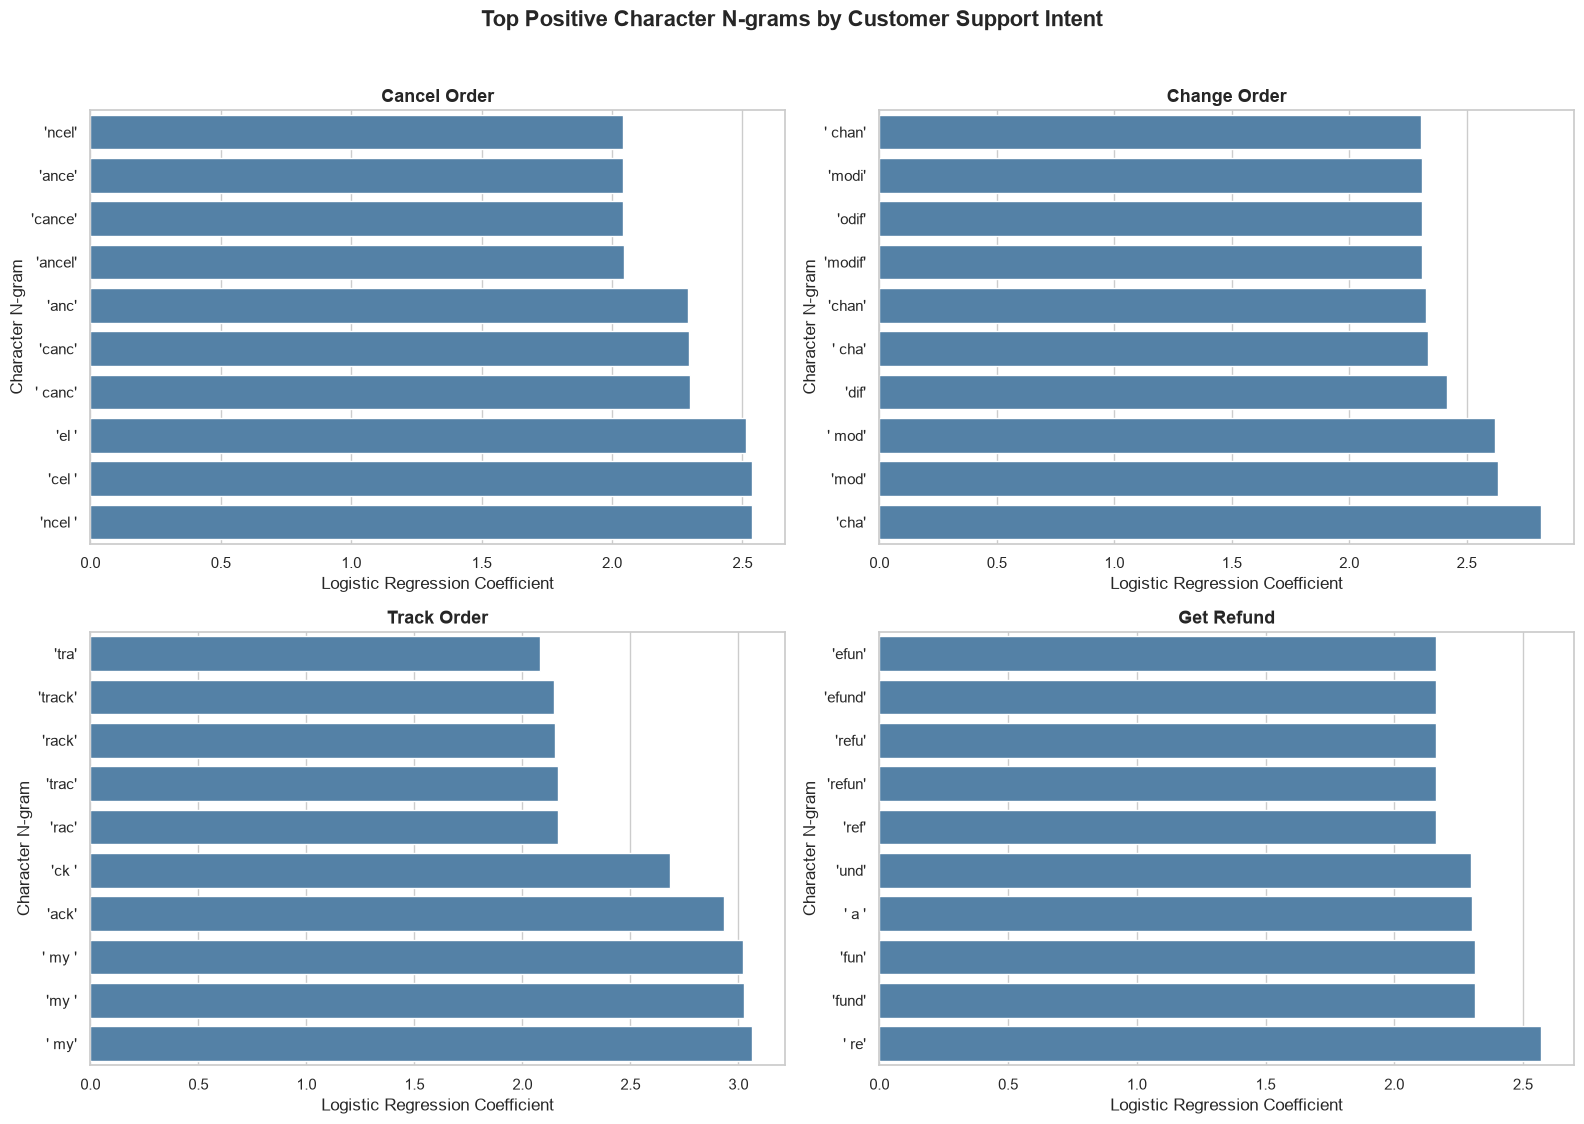

Feature importance figure saved to: ..\reports\figures\intent_character_ngram_importance.png


In [6]:
selected_intents = [
    "cancel_order",
    "change_order",
    "track_order",
    "get_refund"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, intent in zip(axes.flat, selected_intents):
    intent_features = (
        top_features_df[top_features_df["Intent"] == intent]
        .sort_values("Coefficient", ascending=True)
        .copy()
    )

    intent_features["Display N-gram"] = (
        intent_features["Character N-gram"]
        .apply(repr)
    )

    sns.barplot(
        data=intent_features,
        x="Coefficient",
        y="Display N-gram",
        color="steelblue",
        ax=ax
    )

    ax.set_title(
        intent.replace("_", " ").title(),
        fontsize=13,
        fontweight="bold"
    )
    ax.set_xlabel("Logistic Regression Coefficient")
    ax.set_ylabel("Character N-gram")

plt.suptitle(
    "Top Positive Character N-grams by Customer Support Intent",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

feature_importance_path = figures_dir / "intent_character_ngram_importance.png"

plt.savefig(
    feature_importance_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Feature importance figure saved to: {feature_importance_path}")

#### Visualizing the Most Influential Character N-grams

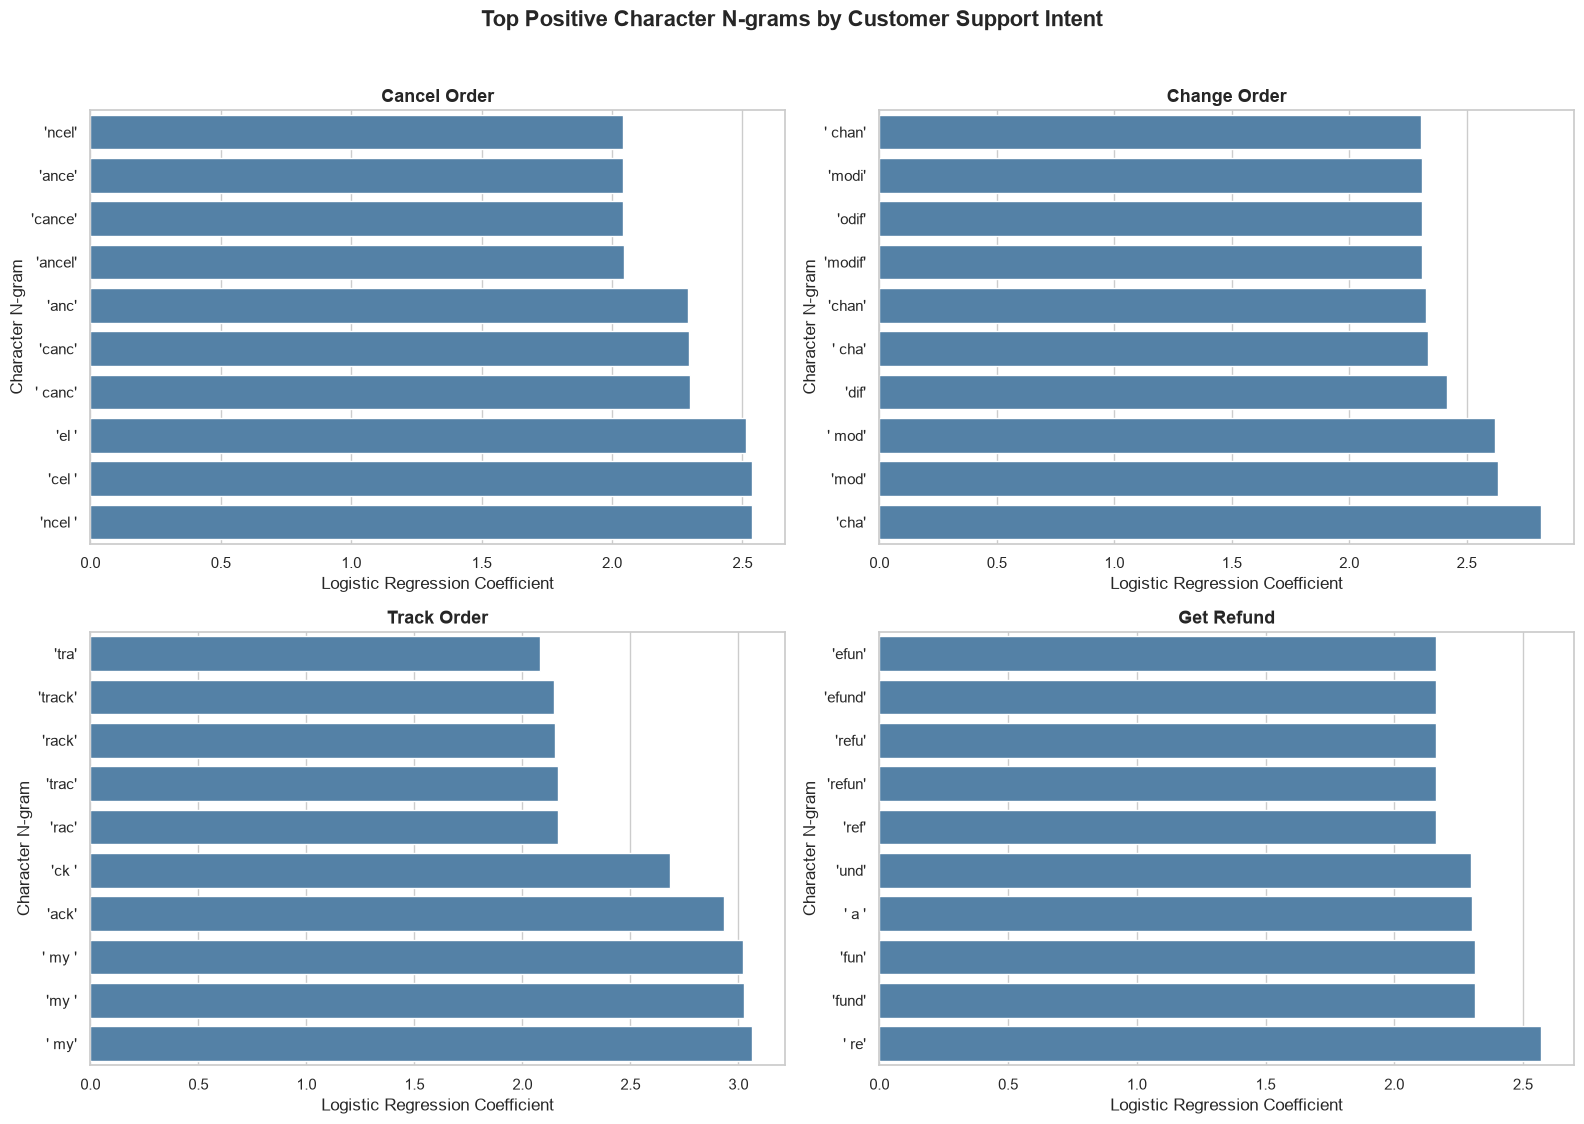

Feature importance figure saved to: ..\reports\figures\intent_character_ngram_importance.png


In [7]:
selected_intents = [
    "cancel_order",
    "change_order",
    "track_order",
    "get_refund"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, intent in zip(axes.flat, selected_intents):
    intent_features = (
        top_features_df[top_features_df["Intent"] == intent]
        .sort_values("Coefficient", ascending=True)
        .copy()
    )

    intent_features["Display N-gram"] = (
        intent_features["Character N-gram"]
        .apply(repr)
    )

    sns.barplot(
        data=intent_features,
        x="Coefficient",
        y="Display N-gram",
        color="steelblue",
        ax=ax
    )

    ax.set_title(
        intent.replace("_", " ").title(),
        fontsize=13,
        fontweight="bold"
    )
    ax.set_xlabel("Logistic Regression Coefficient")
    ax.set_ylabel("Character N-gram")

plt.suptitle(
    "Top Positive Character N-grams by Customer Support Intent",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

feature_importance_path = figures_dir / "intent_character_ngram_importance.png"

plt.savefig(
    feature_importance_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Feature importance figure saved to: {feature_importance_path}")

#### Saving Class-Specific Feature Importance Results

In [8]:
feature_importance_csv_path = (
    processed_dir / "intent_character_ngram_importance.csv"
)

top_features_df.to_csv(
    feature_importance_csv_path,
    index=False
)

print("Class-specific feature importance results saved successfully.")
print(f"Path: {feature_importance_csv_path}")
print(f"Intent classes documented: {top_features_df['Intent'].nunique()}")
print(f"Features per intent: {top_n}")
print(f"Total feature records: {len(top_features_df)}")

Class-specific feature importance results saved successfully.
Path: ..\data\processed\intent_character_ngram_importance.csv
Intent classes documented: 27
Features per intent: 10
Total feature records: 270


## 4. Local Prediction Explainability

#### Analyzing Feature Contributions for Individual Predictions

In [9]:
sample_utterance = "I want to cancel my order"

sample_vector = tfidf_vectorizer.transform([sample_utterance])

predicted_intent = final_pipeline.predict([sample_utterance])[0]
prediction_probabilities = final_pipeline.predict_proba(
    [sample_utterance]
)[0]

predicted_class_idx = np.where(
    intent_classes == predicted_intent
)[0][0]

sample_feature_indices = sample_vector.indices
sample_tfidf_values = sample_vector.data

sample_coefficients = coefficients[
    predicted_class_idx, sample_feature_indices
]

feature_contributions = (
    sample_tfidf_values * sample_coefficients
)

local_explanation_df = pd.DataFrame({
    "Character N-gram": feature_names[sample_feature_indices],
    "TF-IDF Value": sample_tfidf_values,
    "Coefficient": sample_coefficients,
    "Contribution": feature_contributions
})

local_explanation_df = (
    local_explanation_df
    .sort_values("Contribution", ascending=False)
    .reset_index(drop=True)
)

print(f"Utterance: {sample_utterance}")
print(f"Predicted Intent: {predicted_intent}")
print(
    f"Predicted Probability: "
    f"{prediction_probabilities[predicted_class_idx]:.4f}"
)
print(f"Active Character N-grams: {len(local_explanation_df)}")

display(local_explanation_df.head(15).round(4))

Utterance: I want to cancel my order
Predicted Intent: cancel_order
Predicted Probability: 0.8021
Active Character N-grams: 43


,Character N-gram,TF-IDF Value,Coefficient,Contribution
0,cel,0.2447,2.5362,0.6206
1,ncel,0.2447,2.5362,0.6206
2,el,0.2430,2.5140,0.6109
3,canc,0.1851,2.2969,0.4251
4,canc,0.1850,2.2957,0.4247
5,anc,0.1849,2.2927,0.4239
6,ancel,0.1853,2.0445,0.3789
7,cance,0.1853,2.0432,0.3787
8,ance,0.1853,2.0419,0.3784
9,ncel,0.1851,2.0404,0.3776


#### Observations
- **The model correctly predicts `cancel_order` with an estimated probability of 80.21%** for the sample utterance.
- **Cancellation-related character n-grams provide the strongest positive contributions**, while order-related patterns provide additional supporting evidence.
- **Key Finding:** Local feature contributions demonstrate how the model combines TF-IDF values and learned coefficients to produce interpretable class scores for individual customer requests.

#### Visualizing Local Feature Contributions

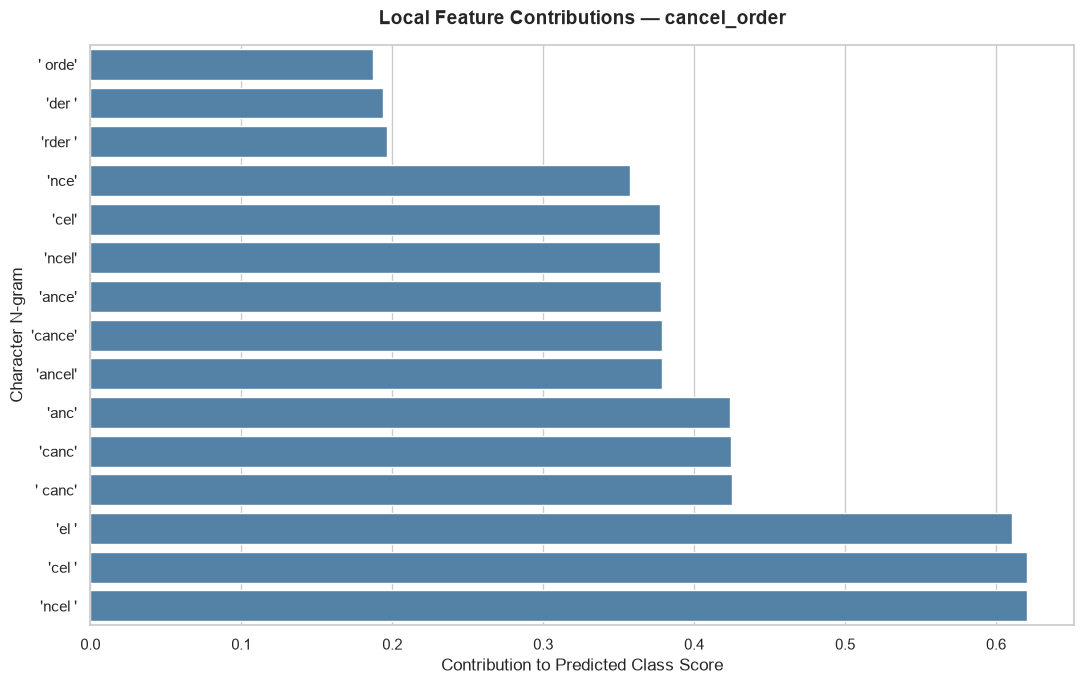

Local explanation figure saved to: ..\reports\figures\local_prediction_feature_contributions.png


In [10]:
top_local_features = (
    local_explanation_df
    .head(15)
    .sort_values("Contribution", ascending=True)
    .copy()
)

top_local_features["Display N-gram"] = (
    top_local_features["Character N-gram"].apply(repr)
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=top_local_features,
    x="Contribution",
    y="Display N-gram",
    color="steelblue",
    ax=ax
)

ax.set_title(
    f"Local Feature Contributions — {predicted_intent}",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Contribution to Predicted Class Score")
ax.set_ylabel("Character N-gram")

plt.tight_layout()

local_explanation_path = (
    figures_dir / "local_prediction_feature_contributions.png"
)

plt.savefig(
    local_explanation_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Local explanation figure saved to: {local_explanation_path}")

## 5. Explaining Misclassified Predictions

#### Investigating an Ambiguous Registration Request

In [11]:
error_utterance = "I can't create a profile"
actual_intent = "registration_problems"

error_vector = tfidf_vectorizer.transform([error_utterance])

error_prediction = final_pipeline.predict([error_utterance])[0]
error_probabilities = final_pipeline.predict_proba(
    [error_utterance]
)[0]

predicted_idx = np.where(
    intent_classes == error_prediction
)[0][0]

actual_idx = np.where(
    intent_classes == actual_intent
)[0][0]

active_indices = error_vector.indices
active_values = error_vector.data

error_explanation_df = pd.DataFrame({
    "Character N-gram": feature_names[active_indices],
    "TF-IDF Value": active_values,
    "Predicted Class Coefficient": coefficients[
        predicted_idx, active_indices
    ],
    "Actual Class Coefficient": coefficients[
        actual_idx, active_indices
    ]
})

error_explanation_df["Predicted Class Contribution"] = (
    error_explanation_df["TF-IDF Value"]
    * error_explanation_df["Predicted Class Coefficient"]
)

error_explanation_df["Actual Class Contribution"] = (
    error_explanation_df["TF-IDF Value"]
    * error_explanation_df["Actual Class Coefficient"]
)

error_explanation_df["Contribution Difference"] = (
    error_explanation_df["Predicted Class Contribution"]
    - error_explanation_df["Actual Class Contribution"]
)

error_explanation_df = (
    error_explanation_df
    .sort_values("Contribution Difference", ascending=False)
    .reset_index(drop=True)
)

print(f"Utterance: {error_utterance}")
print(f"Actual Intent: {actual_intent}")
print(f"Predicted Intent: {error_prediction}")
print(f"Predicted Class Probability: {error_probabilities[predicted_idx]:.4f}")
print(f"Actual Class Probability: {error_probabilities[actual_idx]:.4f}")
print(f"Active Character N-grams: {len(error_explanation_df)}")

display(error_explanation_df.head(15).round(4))

Utterance: I can't create a profile
Actual Intent: registration_problems
Predicted Intent: create_account
Predicted Class Probability: 0.9401
Actual Class Probability: 0.0299
Active Character N-grams: 47


,Character N-gram,TF-IDF Value,Predicted Class Coefficient,Actual Class Coefficient,Predicted Class Contribution,Actual Class Contribution,Contribution Difference
0,eate,0.1567,1.8163,0.2263,0.2847,0.0355,0.2492
1,eate,0.1565,1.8200,0.2437,0.2848,0.0381,0.2467
2,reate,0.1567,1.6976,0.2558,0.2661,0.0401,0.2260
3,prof,0.1524,1.5846,0.1427,0.2415,0.0217,0.2198
4,ofil,0.1525,1.5963,0.1567,0.2434,0.0239,0.2195
5,ofile,0.1526,1.5973,0.1590,0.2437,0.0243,0.2195
6,prof,0.1523,1.5811,0.1412,0.2408,0.0215,0.2193
7,rof,0.1523,1.5811,0.1412,0.2408,0.0215,0.2193
8,ofi,0.1523,1.5911,0.1521,0.2423,0.0232,0.2192
9,ate,0.1539,1.5698,0.1732,0.2415,0.0267,0.2149


#### Observations
- **The model incorrectly predicts `create_account` with 94.01% probability**, while assigning only 2.99% to the correct `registration_problems` intent.
- **Character n-grams associated with "create" and "profile" strongly favor account creation**, outweighing the contextual significance of the phrase "can't".
- **Key Finding:** The model can produce highly confident incorrect predictions when semantically related intents differ primarily through negation or expressions of unsuccessful actions.

#### Visualizing Feature Contributions Behind Misclassification

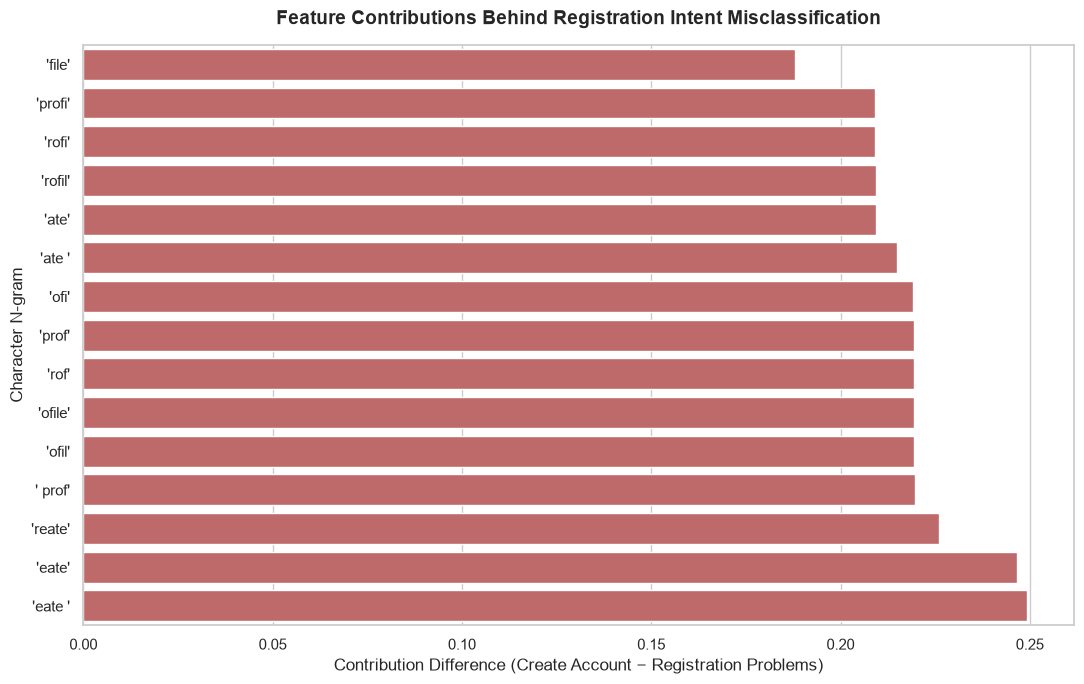

Misclassification explanation figure saved to: ..\reports\figures\registration_misclassification_explanation.png


In [12]:
top_error_features = (
    error_explanation_df
    .head(15)
    .sort_values("Contribution Difference", ascending=True)
    .copy()
)

top_error_features["Display N-gram"] = (
    top_error_features["Character N-gram"].apply(repr)
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=top_error_features,
    x="Contribution Difference",
    y="Display N-gram",
    color="indianred",
    ax=ax
)

ax.set_title(
    "Feature Contributions Behind Registration Intent Misclassification",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Contribution Difference (Create Account − Registration Problems)"
)
ax.set_ylabel("Character N-gram")

plt.tight_layout()

misclassification_explanation_path = (
    figures_dir / "registration_misclassification_explanation.png"
)

plt.savefig(
    misclassification_explanation_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Misclassification explanation figure saved to: "
    f"{misclassification_explanation_path}"
)

## 6. Prediction Probability Analysis

#### Examining the Highest-Probability Intent Predictions

Utterance: I can't create a profile
Actual Intent: registration_problems
Predicted Intent: create_account

Top 10 Predicted Intent Probabilities:


,Intent,Predicted Probability
0,create_account,0.9401
1,registration_problems,0.0299
2,edit_account,0.0125
3,delete_account,0.0049
4,recover_password,0.0022
5,payment_issue,0.0013
6,contact_human_agent,0.0012
7,check_invoices,0.0010
8,review,0.0008
9,switch_account,0.0007


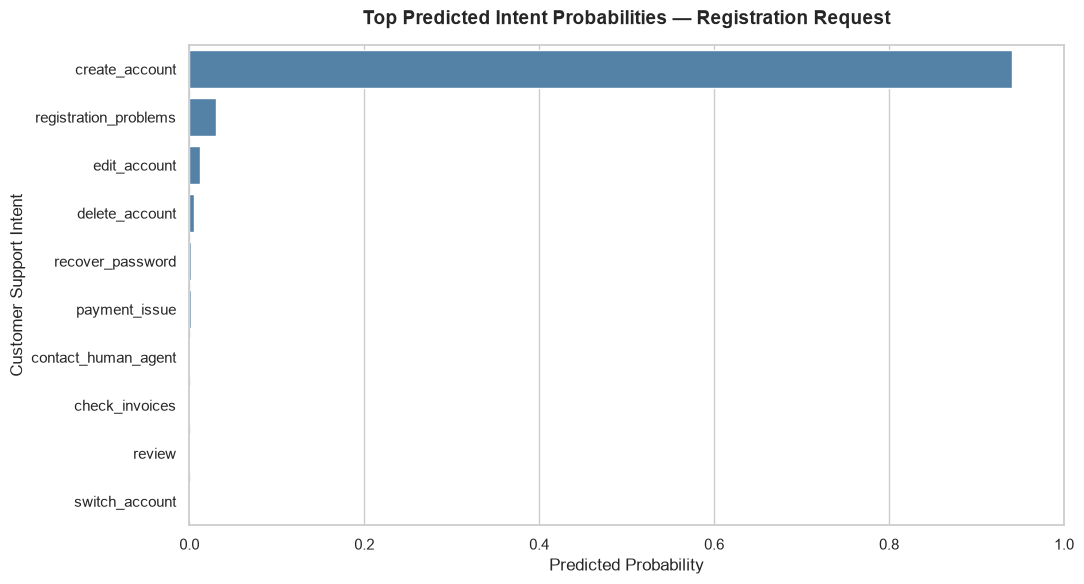

Probability comparison figure saved to: ..\reports\figures\registration_prediction_probabilities.png


In [13]:
probability_df = pd.DataFrame({
    "Intent": intent_classes,
    "Predicted Probability": error_probabilities
})

probability_df = (
    probability_df
    .sort_values("Predicted Probability", ascending=False)
    .reset_index(drop=True)
)

top_probability_df = probability_df.head(10).copy()

print(f"Utterance: {error_utterance}")
print(f"Actual Intent: {actual_intent}")
print(f"Predicted Intent: {error_prediction}")

print("\nTop 10 Predicted Intent Probabilities:")
display(top_probability_df.round(4))

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=top_probability_df,
    x="Predicted Probability",
    y="Intent",
    color="steelblue",
    ax=ax
)

ax.set_title(
    "Top Predicted Intent Probabilities — Registration Request",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Predicted Probability")
ax.set_ylabel("Customer Support Intent")
ax.set_xlim(0, 1)

plt.tight_layout()

probability_figure_path = (
    figures_dir / "registration_prediction_probabilities.png"
)

plt.savefig(
    probability_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Probability comparison figure saved to: {probability_figure_path}")

#### Observations
- **The model assigns 94.01% probability to the incorrect `create_account` intent**, compared with only 2.99% for the correct `registration_problems` intent.
- **Competing intents receive substantially lower probabilities**, indicating a strong preference for account-creation terminology despite the presence of failure-related language.
- **Key Finding:** High-confidence misclassifications highlight the need for caution when interpreting model probabilities, particularly for semantically overlapping intents and negated requests.

#### Saving Local Prediction Explanation Results

In [14]:
local_explanation_csv_path = (
    processed_dir / "local_prediction_feature_contributions.csv"
)

misclassification_explanation_csv_path = (
    processed_dir / "registration_misclassification_contributions.csv"
)

prediction_probabilities_csv_path = (
    processed_dir / "registration_prediction_probabilities.csv"
)

local_explanation_df.to_csv(
    local_explanation_csv_path,
    index=False
)

error_explanation_df.to_csv(
    misclassification_explanation_csv_path,
    index=False
)

probability_df.to_csv(
    prediction_probabilities_csv_path,
    index=False
)

print("Local explainability artifacts saved successfully.\n")
print(f"Correct Prediction Explanation: {local_explanation_csv_path}")
print(f"Misclassification Explanation: {misclassification_explanation_csv_path}")
print(f"Prediction Probabilities: {prediction_probabilities_csv_path}")

print(f"\nCorrect prediction features: {len(local_explanation_df)}")
print(f"Misclassification features: {len(error_explanation_df)}")
print(f"Intent probabilities documented: {len(probability_df)}")

Local explainability artifacts saved successfully.

Correct Prediction Explanation: ..\data\processed\local_prediction_feature_contributions.csv
Misclassification Explanation: ..\data\processed\registration_misclassification_contributions.csv
Prediction Probabilities: ..\data\processed\registration_prediction_probabilities.csv

Correct prediction features: 43
Misclassification features: 47
Intent probabilities documented: 27


## 7. Explainability Summary

#### Summarizing Model Explainability Findings

The explainability analysis examines how the selected Logistic Regression model uses character-level TF-IDF features to classify customer support requests across 27 intents.

**Key Findings:**

- **Global Feature Importance:** The model learns intent-specific character n-grams associated with cancellation, order modification, shipping, refunds, and other customer support activities. The analysis documents the 10 strongest positive coefficients for each of the 27 intents.
- **Local Prediction Explainability:** For the correctly classified utterance "I want to cancel my order," cancellation-related n-grams provide the strongest positive contributions, supporting the predicted `cancel_order` intent.
- **Misclassification Analysis:** For "I can't create a profile," account-creation-related features favor `create_account` over the correct `registration_problems` intent, illustrating difficulty distinguishing related requests when negation changes their meaning.
- **Prediction Confidence:** The incorrect registration prediction receives an estimated probability of 94.01%, demonstrating that high model confidence does not necessarily indicate a correct classification.

#### Acknowledging Explainability Limitations

- **Feature Interpretation:** Character n-grams represent fragments of text rather than complete semantic concepts, limiting the interpretability of individual features.
- **Correlated Features:** Overlapping character n-grams can share similar information, so their coefficients should not be interpreted as independent causal effects.
- **Probability Interpretation:** Predicted probabilities are model estimates and have not been independently assessed for calibration.
- **Generalization:** Explanations are derived from a model trained on structured customer support utterances and may not fully represent its behavior on naturally occurring customer conversations.

**Conclusion:** The explainability analysis demonstrates that Logistic Regression learns meaningful intent-associated character patterns while revealing limitations in handling semantically overlapping requests and negation. These findings complement the model evaluation results and provide a transparent assessment of its predictive behavior.## 7. Explainability Summary

#### Summarizing Model Explainability Findings

The explainability analysis examines how the selected Logistic Regression model uses character-level TF-IDF features to classify customer support requests across 27 intents.

**Key Findings:**

- **Global Feature Importance:** The model learns intent-specific character n-grams associated with cancellation, order modification, shipping, refunds, and other customer support activities. The analysis documents the 10 strongest positive coefficients for each of the 27 intents.
- **Local Prediction Explainability:** For the correctly classified utterance "I want to cancel my order," cancellation-related n-grams provide the strongest positive contributions, supporting the predicted `cancel_order` intent.
- **Misclassification Analysis:** For "I can't create a profile," account-creation-related features favor `create_account` over the correct `registration_problems` intent, illustrating difficulty distinguishing related requests when negation changes their meaning.
- **Prediction Confidence:** The incorrect registration prediction receives an estimated probability of 94.01%, demonstrating that high model confidence does not necessarily indicate a correct classification.

#### Acknowledging Explainability Limitations

- **Feature Interpretation:** Character n-grams represent fragments of text rather than complete semantic concepts, limiting the interpretability of individual features.
- **Correlated Features:** Overlapping character n-grams can share similar information, so their coefficients should not be interpreted as independent causal effects.
- **Probability Interpretation:** Predicted probabilities are model estimates and have not been independently assessed for calibration.
- **Generalization:** Explanations are derived from a model trained on structured customer support utterances and may not fully represent its behavior on naturally occurring customer conversations.

**Conclusion:** The explainability analysis demonstrates that Logistic Regression learns meaningful intent-associated character patterns while revealing limitations in handling semantically overlapping requests and negation. These findings complement the model evaluation results and provide a transparent assessment of its predictive behavior.

#### Verifying Final Explainability Artifacts

In [15]:
explainability_artifacts = {
    "Selected Model": models_dir / "final_logistic_regression_pipeline.joblib",
    "Global Feature Importance": processed_dir / "intent_character_ngram_importance.csv",
    "Global Importance Figure": figures_dir / "intent_character_ngram_importance.png",
    "Local Feature Contributions": processed_dir / "local_prediction_feature_contributions.csv",
    "Local Explanation Figure": figures_dir / "local_prediction_feature_contributions.png",
    "Misclassification Contributions": processed_dir / "registration_misclassification_contributions.csv",
    "Misclassification Figure": figures_dir / "registration_misclassification_explanation.png",
    "Prediction Probabilities": processed_dir / "registration_prediction_probabilities.csv",
    "Probability Comparison Figure": figures_dir / "registration_prediction_probabilities.png"
}

print("Final Explainability Artifact Verification\n")

for artifact_name, artifact_path in explainability_artifacts.items():
    status = "Found" if artifact_path.is_file() else "Missing"
    print(f"{artifact_name}: {status}")

available_artifacts = sum(
    path.is_file() for path in explainability_artifacts.values()
)

print(f"\nArtifacts verified: {available_artifacts}/{len(explainability_artifacts)}")

if available_artifacts == len(explainability_artifacts):
    print("\nModel explainability completed successfully.")
else:
    print("\nSome artifacts are missing. Review the paths above.")

Final Explainability Artifact Verification

Selected Model: Found
Global Feature Importance: Found
Global Importance Figure: Found
Local Feature Contributions: Found
Local Explanation Figure: Found
Misclassification Contributions: Found
Misclassification Figure: Found
Prediction Probabilities: Found
Probability Comparison Figure: Found

Artifacts verified: 9/9

Model explainability completed successfully.
